# สรุปผลวัตถุประสงค์ข้อ 1 และข้อ 2

ไฟล์นี้รวบรวมผลที่บันทึกไว้จากการทดลอง ทั้งราคาเช่าและ Market & Occupancy Forecasting

# ส่วนที่ 1: สรุปผลแบบจำลองราคาค่าเช่า

Notebook นี้รวบรวมผลจากไฟล์ที่สร้างโดยขั้นตอนเทรนโมเดล เพื่อเปรียบเทียบ Stepwise Multiple Linear Regression, Gradient Boosting Regressor, Random Forest Regressor, K-Nearest Neighbors Regressor และ Artificial Neural Network โดยไม่ฝึกโมเดลซ้ำและไม่แก้ไขชุด Test

**หมายเหตุส่วนที่ 1:** ข้อความและคะแนนด้านล่างเป็นสรุปเดิมของราคาเช่า หากไฟล์ผลราคาเช่าขาด ระบบจะข้ามตาราง/กราฟข้อ 1 คะแนนในข้อความเดิมยังไม่ได้ตรวจยืนยันจากไฟล์ในเครื่องนี้ ส่วนข้อ 2 โหลดผลจริงที่มีอยู่และรันต่อได้


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

METRICS_PATH = PROJECT_ROOT / 'reports' / 'metrics' / 'rental_price_model_metrics.csv'
TABLE_DIR = PROJECT_ROOT / 'reports' / 'tables'
METADATA_PATH = PROJECT_ROOT / 'models' / 'rental_price' / 'rental_price_metadata.json'

rental_required_paths = [METRICS_PATH, METADATA_PATH] + [
    TABLE_DIR / name for name in [
        'rental_price_gradient_boosting_tuning.csv', 'rental_price_random_forest_tuning.csv',
        'rental_price_knn_tuning.csv', 'rental_price_ann_tuning.csv',
        'rental_price_random_forest_importance.csv',
    ]
]
rental_missing_paths = [path for path in rental_required_paths if not path.exists()]
rental_results_available = not rental_missing_paths
if not rental_results_available:
    print('ยังสรุปข้อ 1 จากไฟล์ผลจริงไม่ได้: ขาดไฟล์ต่อไปนี้')
    for missing_path in rental_missing_paths:
        print(missing_path)
    print('ข้ามตาราง/กราฟข้อ 1 และรันผลวัตถุประสงค์ข้อ 2 ต่อได้')
else:
    metrics = pd.read_csv(METRICS_PATH)
    metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
    gbr_tuning = pd.read_csv(TABLE_DIR / 'rental_price_gradient_boosting_tuning.csv')
    rf_tuning = pd.read_csv(TABLE_DIR / 'rental_price_random_forest_tuning.csv')
    knn_tuning = pd.read_csv(TABLE_DIR / 'rental_price_knn_tuning.csv')
    ann_tuning = pd.read_csv(TABLE_DIR / 'rental_price_ann_tuning.csv')
    rf_importance = pd.read_csv(TABLE_DIR / 'rental_price_random_forest_importance.csv')
    
    print('โมเดลที่เลือก:', metadata['winner_model'])

ยังสรุปข้อ 1 จากไฟล์ผลจริงไม่ได้: ขาดไฟล์ต่อไปนี้
D:\final project_\reports\metrics\rental_price_model_metrics.csv
D:\final project_\reports\tables\rental_price_gradient_boosting_tuning.csv
D:\final project_\reports\tables\rental_price_random_forest_tuning.csv
D:\final project_\reports\tables\rental_price_knn_tuning.csv
D:\final project_\reports\tables\rental_price_ann_tuning.csv
D:\final project_\reports\tables\rental_price_random_forest_importance.csv
ข้ามตาราง/กราฟข้อ 1 และรันผลวัตถุประสงค์ข้อ 2 ต่อได้


## ผลการเปรียบเทียบ

ใช้ MAE เป็นเกณฑ์หลักในการเลือกโมเดลจาก Validation ส่วน RMSE และ R² แสดงเพื่อประกอบการวิเคราะห์

In [2]:
if rental_results_available:
    metric_table = metrics.copy()
    metric_table[['mae', 'rmse']] = metric_table[['mae', 'rmse']].round(2)
    metric_table['r2'] = metric_table['r2'].round(4)
    display(metric_table)

In [3]:
if rental_results_available:
    plt.figure(figsize=(9, 5))
    sns.barplot(data=metrics, x='model', y='mae', hue='split')
    plt.title('MAE ของแบบจำลองราคาค่าเช่า')
    plt.xlabel('แบบจำลอง')
    plt.ylabel('MAE (บาทต่อเดือน)')
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

Random Forest มี Validation MAE ต่ำที่สุด 713.92 บาท จึงได้รับเลือกตามเกณฑ์ที่กำหนดก่อนเปิดชุด Test โดย KNN มี Validation MAE 808.07 บาท และ ANN มี 870.11 บาท บน Test นั้น Random Forest มี MAE ต่ำที่สุด 1,020.73 บาท อย่างไรก็ตาม Gradient Boosting มี Test RMSE ต่ำกว่าและ Test R² สูงกว่าเล็กน้อย จึงไม่ควรสรุปว่า Random Forest ดีกว่าในทุกตัวชี้วัด

## Hyperparameters และผลการจูนของโมเดล

In [4]:
if rental_results_available:
    for model_name, parameter_key, tuning_data in [
        ('Gradient Boosting', 'gradient_boosting_params', gbr_tuning),
        ('Random Forest', 'random_forest_params', rf_tuning),
        ('KNN', 'knn_params', knn_tuning),
        ('ANN', 'ann_params', ann_tuning),
    ]:
        print(model_name)
        display(pd.Series(metadata[parameter_key]).to_frame('selected_value'))
        display(tuning_data.sort_values('mean_validation_mae').head(5).round(2))

## Feature Importance

Feature Importance ของ Random Forest ใช้สำหรับดูว่าตัวแปรใดมีส่วนช่วยในการแบ่งข้อมูลของต้นไม้มาก แต่ไม่ได้แปลว่าตัวแปรนั้นเป็นสาเหตุของราคาเช่าโดยตรง

In [5]:
if rental_results_available:
    top_importance = rf_importance.head(10).sort_values('importance')
    
    plt.figure(figsize=(9, 6))
    plt.barh(top_importance['feature'], top_importance['importance'])
    plt.title('10 ตัวแปรสำคัญของ Random Forest')
    plt.xlabel('Feature importance')
    plt.ylabel('ตัวแปรหลังการแปลงข้อมูล')
    plt.tight_layout()
    plt.show()
    
    display(rf_importance.head(10))

## ช่วงความคลาดเคลื่อนและข้อจำกัด

In [6]:
if rental_results_available:
    error_reference = metadata['prediction_error_reference']
    summary = pd.DataFrame({
        'รายการ': ['Validation P50', 'Validation P75', 'Validation P90', 'Test coverage ของ P75'],
        'ค่า': [
            f"{error_reference['absolute_error_quantiles_baht']['p50']:.2f} บาท",
            f"{error_reference['absolute_error_quantiles_baht']['p75']:.2f} บาท",
            f"{error_reference['absolute_error_quantiles_baht']['p90']:.2f} บาท",
            f"{error_reference['test_coverage']:.2%}",
        ],
    })
    display(summary)

ค่า P75 จาก Validation ครอบคลุมข้อมูล Test จริงเพียง 58.80% ซึ่งต่ำกว่าเป้าหมาย 75% จึงควรเรียกว่า **ช่วงความคลาดเคลื่อนอ้างอิง** ไม่ใช่ Prediction Interval หรือช่วงความเชื่อมั่น นอกจากนี้ Test MAE สูงกว่า Validation MAE แสดงว่ารูปแบบราคาในช่วงเวลาล่าสุดเปลี่ยนไปจากข้อมูลที่ใช้เลือกโมเดล

## ข้อสรุป

เมื่อเปรียบเทียบทั้ง 5 โมเดล Random Forest Regressor ยังคงเป็นโมเดลที่เลือกใช้ใน Price Engine เพราะมี Validation MAE ต่ำที่สุด 713.92 บาท และ Test MAE ต่ำที่สุด 1,020.73 บาท โมเดลนี้ทำนาย `rent` ซึ่งเป็นค่าเช่าตามสัญญา โดย `date_start` หมายถึงวันที่เริ่มสัญญาเช่า ผลลัพธ์ควรใช้เป็นข้อมูลประกอบการตัดสินใจร่วมกับสภาพห้องและสถานการณ์ตลาด

# ส่วนที่ 2: สรุปผล Market & Occupancy Forecasting

วัตถุประสงค์: เพื่อพัฒนาโมเดลพยากรณ์สภาวะตลาดและอัตราการเข้าพักล่วงหน้า

รวบรวมผลจาก Notebook 02 โดยโหลดตารางที่บันทึกไว้ ไม่ฝึกหรือจูนซ้ำ
ทดลอง SARIMA, SARIMAX, Random Forest และสอง baseline: Naive กับ Seasonal Naive
สรุป 4 targets แยกตามระยะพยากรณ์ 1, 4 และ 12 สัปดาห์

ผลหลักของ **รอบหลังจูนเป็น Validation** ส่วน Test ที่แสดงเป็น **รอบแรกก่อนจูน**
โมเดลหลังจูนยังไม่มี final holdout ใหม่ ทั้งหมดใช้ข้อมูลจำลองของโครงงาน

## 1. เตรียมเครื่องมือและโหลดผลทดลอง

อ่านโค้ดตามลำดับ: เตรียมโฟลเดอร์ → โหลดตาราง → เลือกคอลัมน์ → เปรียบเทียบ → วาดกราฟ → สรุป
ใช้ชื่อตัวแปรตามสิ่งที่เก็บ เช่น `validation_scores` เก็บคะแนน และ `winning_models` เก็บโมเดลที่ชนะ

คำที่ใช้บ่อย:
- **target**: ตัวแปรที่จะพยากรณ์ เช่น occupancy
- **horizon**: จำนวนสัปดาห์ที่พยากรณ์ล่วงหน้า
- **MAE**: ค่าเฉลี่ยความคลาดเคลื่อนสัมบูรณ์ ยิ่งต่ำยิ่งดี
- **forecast_origin**: วันที่เริ่มพยากรณ์
- **target_date**: วันที่ต้องการทราบค่าล่วงหน้า

โค้ดนี้ใช้ผลจาก Notebook 02 ที่บันทึกไว้แล้ว ไม่ต้องฝึกโมเดลซ้ำ

In [7]:
# เตรียมเครื่องมือที่ใช้ในส่วนข้อ 2
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

In [8]:
# กำหนดตำแหน่งอ่านผลและตำแหน่งบันทึกสรุป
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

evaluation_dir = project_root / "reports/market_occupancy/evaluation"
tuning_dir = project_root / "reports/market_occupancy/tuning"
output_dir = project_root / "reports/market_occupancy/final_results"
figure_dir = output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

In [9]:
# โหลดตาราง: คะแนน / ผู้ชนะ / ผลจูน / คำทำนาย / ข้อมูลการทดลอง
validation_scores = pd.read_csv(tuning_dir / "tuned_validation_metrics.csv")
winning_models = pd.read_csv(tuning_dir / "tuned_winners.csv")
before_after = pd.read_csv(tuning_dir / "validation_before_after.csv")
cv_scores = pd.read_csv(tuning_dir / "cv_metrics.csv")
selected_parameters = pd.read_csv(tuning_dir / "selected_parameter_table.csv")
cv_design = pd.read_csv(tuning_dir / "cv_design.csv")
initial_test_results = pd.read_csv(evaluation_dir / "selected_model_summary.csv")
short_history_results = pd.read_csv(evaluation_dir / "test_short_history_metrics.csv")
validation_predictions = pd.read_csv(
    tuning_dir / "validation_Naive_SeasonalNaive_SARIMA_SARIMAX_RandomForest.csv",
    parse_dates=["forecast_origin", "target_date"],
)
tuned_model_info = json.loads(
    (project_root / "models/market_occupancy/tuned/model_metadata.json").read_text(encoding="utf-8")
)
data_info = json.loads(
    (project_root / "data/modeling/market_occupancy/forecast_feature_metadata.json").read_text(encoding="utf-8")
)
model_names = ["Naive", "SeasonalNaive", "SARIMA", "SARIMAX", "RandomForest"]
target_names = ["occupancy", "n_searchers", "n_listings_open", "median_asking_rent"]
horizons = [1, 4, 12]
print("สถานะ:", tuned_model_info["status"])
print("โมเดลสุดท้ายฝึกถึง:", tuned_model_info["trained_through"])

สถานะ: tuned_and_validation_selected_not_new_holdout_tested
โมเดลสุดท้ายฝึกถึง: 2026-03-31


## 2. สรุปการออกแบบการทดลอง

ใช้ weekly_market เป็นตารางหลักและข้อมูลโครงการประกอบ occupancy คือห้องที่มีผู้เช่า / ห้องทั้งหมด
SARIMA/SARIMAX ฝึกแยกโครงการ ส่วน Random Forest รวมหลายโครงการด้วย lag features
แบ่งชุดตาม target_date และจำกัดข้อมูลฝึกให้ทราบแล้ว ณ forecast origin
เกณฑ์ประวัติ 104 จุดและฤดูกาล 52 สัปดาห์เป็นค่าตั้งต้นของโครงงาน

In [10]:
# ใช้รายการคู่ [ชื่อรายการ, รายละเอียด] เพื่อให้เห็นว่าแต่ละค่าจับคู่กับอะไร
cv_dates = sorted(cv_design["forecast_origin"].unique())
design_rows = [
    ["Targets", ", ".join(target_names)],
    ["Horizons", "1, 4, 12 สัปดาห์"],
    ["Train end", data_info["train_end"]],
    ["Validation end", data_info["validation_end"]],
    ["Test end รอบแรก", data_info["test_end"]],
    ["TrainCV origins", ", ".join(cv_dates)],
    ["Validation origin หลังจูนเริ่มได้", "2025-11-25 (คำตอบ CV สุดท้ายทราบแล้ว)"],
    ["เกณฑ์เลือก", "พารามิเตอร์: TrainCV MAE; family: Validation MAE"],
    ["หน่วย occupancy", "จุดเปอร์เซ็นต์"],
]
experiment_design = pd.DataFrame(design_rows, columns=["รายการ", "รายละเอียด"])
display(experiment_design)

,รายการ,รายละเอียด
0,Targets,"occupancy, n_searchers, n_listings_open, media..."
1,Horizons,"1, 4, 12 สัปดาห์"
2,Train end,2025-12-31
3,Validation end,2026-03-31
4,Test end รอบแรก,2026-06-30
5,TrainCV origins,"2024-12-31, 2025-04-01, 2025-07-01, 2025-09-02"
6,Validation origin หลังจูนเริ่มได้,2025-11-25 (คำตอบ CV สุดท้ายทราบแล้ว)
7,เกณฑ์เลือก,พารามิเตอร์: TrainCV MAE; family: Validation MAE
8,หน่วย occupancy,จุดเปอร์เซ็นต์


## 3. เปรียบเทียบ 5 วิธีหลังจูนบน Validation

อ่าน MAE/RMSE แยก target เพราะแต่ละตัวมีหน่วยต่างกัน ค่า MAE ต่ำกว่าหมายถึงผิดพลาดน้อยกว่า
ทุกวิธีใน target/horizon เดียวกันใช้กรณีประเมินชุดเดียวกัน โดยก่อน/หลังจูนก็ใช้แถวตรงกัน
occupancy MAE 1 จุดเปอร์เซ็นต์หมายถึงคลาดเคลื่อนเฉลี่ย เช่น 90% เทียบกับ 91%

In [11]:
# เลือกเฉพาะคอลัมน์ที่จำเป็นสำหรับอ่านผล
score_columns = ["target", "horizon_weeks", "method", "MAE", "RMSE", "unit", "n_predictions"]

for target in target_names:
    # กรองคะแนนเฉพาะ target นี้ เช่น occupancy
    target_scores = validation_scores[validation_scores["target"] == target]
    target_scores = target_scores[score_columns]

    # เรียงระยะพยากรณ์ก่อน แล้วเรียง MAE จากน้อยไปมาก
    target_scores = target_scores.sort_values(["horizon_weeks", "MAE"])
    print("Target:", target)
    display(target_scores.round(4))

Target: occupancy


,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions
47,occupancy,1,SARIMA,0.4920,0.6339,percentage points,156
46,occupancy,1,RandomForest,0.5046,0.6334,percentage points,156
48,occupancy,1,SARIMAX,0.5190,0.6555,percentage points,156
45,occupancy,1,Naive,0.5670,0.7271,percentage points,156
49,occupancy,1,SeasonalNaive,1.3392,1.8034,percentage points,156
53,occupancy,4,SARIMAX,0.9809,1.2673,percentage points,148
52,occupancy,4,SARIMA,1.0100,1.2514,percentage points,148
51,occupancy,4,RandomForest,1.1452,1.4617,percentage points,148
54,occupancy,4,SeasonalNaive,1.3297,1.7977,percentage points,148
50,occupancy,4,Naive,1.5266,1.9093,percentage points,148


Target: n_searchers


,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions
32,n_searchers,1,SARIMA,4.4084,6.0526,count,156
34,n_searchers,1,SeasonalNaive,4.4487,6.0500,count,156
33,n_searchers,1,SARIMAX,4.8569,6.6634,count,156
30,n_searchers,1,Naive,5.7500,8.9740,count,156
31,n_searchers,1,RandomForest,7.3873,9.4251,count,156
36,n_searchers,4,RandomForest,3.5657,4.6855,count,148
39,n_searchers,4,SeasonalNaive,4.5203,6.1430,count,148
37,n_searchers,4,SARIMA,4.5600,6.1981,count,148
38,n_searchers,4,SARIMAX,5.1838,7.0605,count,148
35,n_searchers,4,Naive,10.4662,15.5318,count,148


Target: n_listings_open


,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions
17,n_listings_open,1,SARIMA,3.9876,5.2691,count,156
16,n_listings_open,1,RandomForest,4.1188,5.6130,count,156
18,n_listings_open,1,SARIMAX,4.2139,5.4848,count,156
15,n_listings_open,1,Naive,4.8462,6.6881,count,156
19,n_listings_open,1,SeasonalNaive,9.6538,12.7747,count,156
22,n_listings_open,4,SARIMA,8.5354,10.8008,count,148
23,n_listings_open,4,SARIMAX,8.5989,10.9863,count,148
24,n_listings_open,4,SeasonalNaive,9.8581,13.0262,count,148
21,n_listings_open,4,RandomForest,11.5205,16.2510,count,148
20,n_listings_open,4,Naive,14.0338,19.8795,count,148


Target: median_asking_rent


,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions
0,median_asking_rent,1,Naive,123.0769,196.0262,baht/month,156
1,median_asking_rent,1,RandomForest,139.4767,205.5230,baht/month,156
2,median_asking_rent,1,SARIMA,201.9876,285.7089,baht/month,156
3,median_asking_rent,1,SARIMAX,215.5285,309.2720,baht/month,156
4,median_asking_rent,1,SeasonalNaive,387.8846,485.4723,baht/month,156
6,median_asking_rent,4,RandomForest,262.0789,321.6435,baht/month,148
7,median_asking_rent,4,SARIMA,330.8501,437.9338,baht/month,148
5,median_asking_rent,4,Naive,343.0743,442.0604,baht/month,148
8,median_asking_rent,4,SARIMAX,356.0686,490.5176,baht/month,148
9,median_asking_rent,4,SeasonalNaive,389.6959,487.0445,baht/month,148


## 4. โมเดลที่เลือกแยกตาม target และ horizon

เลือกจาก Validation MAE รวม baseline ด้วย จึงไม่มีโมเดลเดียวที่ชนะทุกงาน
คอลัมน์ MAE ลดลงจาก Naive (%) ใช้ baseline Naive บนกรณีเดียวกัน ค่าติดลบคือแย่กว่า Naive
ตารางนี้เป็นผล Validation หลังจูน ไม่ใช่ผล Test ของโมเดลหลังจูน

In [12]:
# 1. นำคะแนน Naive มาเป็นค่าตั้งต้นสำหรับเปรียบเทียบ
naive_scores = validation_scores[validation_scores["method"] == "Naive"]
naive_scores = naive_scores[["target", "horizon_weeks", "MAE"]]
naive_scores = naive_scores.rename(columns={"MAE": "Naive_MAE"})

# 2. จับคู่คะแนนผู้ชนะกับ Naive ของ target และ horizon เดียวกัน
# validate ตรวจว่าจับคู่ได้หนึ่งแถวต่อหนึ่งแถว ไม่เกิดแถวซ้ำ
selected_results = winning_models[score_columns].merge(
    naive_scores, on=["target", "horizon_weeks"], validate="one_to_one"
)

# 3. คำนวณว่า MAE ลดลงจาก Naive กี่เปอร์เซ็นต์
mae_reductions = []
for _, row in selected_results.iterrows():
    if row["Naive_MAE"] > 0:
        reduction = 100 * (row["Naive_MAE"] - row["MAE"]) / row["Naive_MAE"]
    else:
        reduction = np.nan  # หลีกเลี่ยงการหารด้วยศูนย์
    mae_reductions.append(reduction)

selected_results["MAE_reduction_vs_Naive_pct"] = mae_reductions
selected_results = selected_results.sort_values(["target", "horizon_weeks"])
display(selected_results.round(4))

,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions,Naive_MAE,MAE_reduction_vs_Naive_pct
0,median_asking_rent,1,Naive,123.0769,196.0262,baht/month,156,123.0769,0.0000
1,median_asking_rent,4,RandomForest,262.0789,321.6435,baht/month,148,343.0743,23.6087
2,median_asking_rent,12,RandomForest,253.0383,320.7927,baht/month,68,685.5147,63.0878
3,n_listings_open,1,SARIMA,3.9876,5.2691,count,156,4.8462,17.7157
4,n_listings_open,4,SARIMA,8.5354,10.8008,count,148,14.0338,39.1798
5,n_listings_open,12,SeasonalNaive,12.6912,16.6225,count,68,30.1324,57.8819
6,n_searchers,1,SARIMA,4.4084,6.0526,count,156,5.7500,23.3320
7,n_searchers,4,RandomForest,3.5657,4.6855,count,148,10.4662,65.9312
8,n_searchers,12,SARIMA,3.5294,4.6873,count,68,26.9412,86.8996
9,occupancy,1,SARIMA,0.4920,0.6339,percentage points,156,0.5670,13.2247


## 5. ผลก่อนและหลังจูนบนแถวเดียวกัน

ค่า mae_improvement = MAE ก่อนจูน − MAE หลังจูน ค่าบวกคือดีขึ้น
ห้ามนำ Validation h=12 ในตารางรอบแรกทั้งชุดมาเทียบตรง ๆ เพราะรอบจูนกรอง origin เพิ่ม
ตาราง before/after ที่โหลดไว้คำนวณใหม่บนชุดแถวร่วมกันทั้งสองรอบแล้ว

In [13]:
# baseline ไม่มีพารามิเตอร์ให้จูน จึงสรุปเฉพาะ 3 โมเดลที่จูนจริง
tuned_model_names = ["SARIMA", "SARIMAX", "RandomForest"]
tuning_changes = before_after[before_after["method"].isin(tuned_model_names)].copy()

# ถ้าคะแนนต่างกันเล็กมาก (ต่ำกว่า 1e-10) ถือว่าเท่าเดิม
change_labels = []
for improvement in tuning_changes["mae_improvement"]:
    if improvement > 1e-10:
        change_labels.append("ดีขึ้น")
    elif improvement < -1e-10:
        change_labels.append("แย่ลง")
    else:
        change_labels.append("เท่าเดิม")

tuning_changes["ผลหลังจูน"] = change_labels
change_counts = tuning_changes["ผลหลังจูน"].value_counts()
change_counts = change_counts.reindex(["ดีขึ้น", "แย่ลง", "เท่าเดิม"], fill_value=0)
display(change_counts.rename("จำนวนงาน").to_frame())

comparison_columns = ["target", "horizon_weeks", "method", "MAE_before", "MAE_after",
                      "mae_improvement", "unit_after", "n_predictions_after", "ผลหลังจูน"]
display(tuning_changes[comparison_columns].round(4))

# คะแนนก่อน/หลังต้องใช้จำนวนกรณีเท่ากัน จึงจะเปรียบเทียบได้
same_case_counts = before_after["n_predictions_before"] == before_after["n_predictions_after"]
assert same_case_counts.all(), "จำนวนกรณีก่อนและหลังจูนไม่ตรงกัน"

,จำนวนงาน
ผลหลังจูน,
ดีขึ้น,13
แย่ลง,10
เท่าเดิม,13


,target,horizon_weeks,method,MAE_before,MAE_after,mae_improvement,unit_after,n_predictions_after,ผลหลังจูน
1,median_asking_rent,1,RandomForest,135.9278,139.4767,-3.5489,baht/month,156,แย่ลง
2,median_asking_rent,1,SARIMA,194.6334,201.9876,-7.3541,baht/month,156,แย่ลง
3,median_asking_rent,1,SARIMAX,215.5285,215.5285,0.0000,baht/month,156,เท่าเดิม
6,median_asking_rent,4,RandomForest,263.7193,262.0789,1.6405,baht/month,148,ดีขึ้น
7,median_asking_rent,4,SARIMA,328.8155,330.8501,-2.0346,baht/month,148,แย่ลง
8,median_asking_rent,4,SARIMAX,346.8118,356.0686,-9.2568,baht/month,148,แย่ลง
11,median_asking_rent,12,RandomForest,257.8814,253.0383,4.8431,baht/month,68,ดีขึ้น
12,median_asking_rent,12,SARIMA,349.7202,349.7202,0.0000,baht/month,68,เท่าเดิม
13,median_asking_rent,12,SARIMAX,358.3752,358.3752,0.0000,baht/month,68,เท่าเดิม
16,n_listings_open,1,RandomForest,4.4004,4.1188,0.2815,count,156,ดีขึ้น


## 6. Hyperparameters และผล TrainCV

SARIMA/SARIMAX เปรียบเทียบ order 3 แบบโดยคง seasonal_order=(0,1,0,52)
Random Forest เปรียบเทียบ 3 ชุดพารามิเตอร์ เป็นการค้นหาแบบจำกัดบน 4 origins
CV_MAE ของ occupancy แสดงเป็นจุดเปอร์เซ็นต์ ส่วน targets อื่นใช้หน่วยเดิม
coverage เป็นสัดส่วนที่คืนคำทำนายครบ ไม่ใช่ coverage ของ Prediction Interval

In [14]:
# ตารางแรก: พารามิเตอร์ที่เลือกไว้สำหรับแต่ละงาน
parameter_table = selected_parameters.sort_values(["target", "horizon_weeks", "method"])
display(parameter_table.round(4))

# ตารางที่สอง: คะแนนของทั้ง 3 candidates ที่ทดลองใน TrainCV
cv_table = cv_scores.copy()
cv_table["CV_MAE"] = cv_table["cv_mae_raw"]

# occupancy เก็บเป็นสัดส่วน 0–1 จึงคูณ 100 เพื่อรายงานเป็นจุดเปอร์เซ็นต์
is_occupancy = cv_table["target"] == "occupancy"
cv_table.loc[is_occupancy, "CV_MAE"] = cv_table.loc[is_occupancy, "CV_MAE"] * 100

cv_columns = ["target", "horizon_weeks", "method", "candidate_id", "CV_MAE",
              "n_folds", "n_predictions", "coverage"]
cv_table = cv_table[cv_columns]
cv_table = cv_table.sort_values(["target", "horizon_weeks", "method", "CV_MAE"])
display(cv_table.round(4))

,method,target,horizon_weeks,candidate_id,parameters,CV_MAE
27,RandomForest,median_asking_rent,1,1,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa...",319.2071
31,SARIMA,median_asking_rent,1,2,"{""order"": [1, 0, 1], ""seasonal_order"": [0, 1, ...",571.8161
32,SARIMAX,median_asking_rent,1,0,"{""order"": [1, 0, 0], ""seasonal_order"": [0, 1, ...",575.4818
28,RandomForest,median_asking_rent,4,1,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa...",416.8027
30,SARIMA,median_asking_rent,4,2,"{""order"": [1, 0, 1], ""seasonal_order"": [0, 1, ...",482.5086
29,SARIMAX,median_asking_rent,4,2,"{""order"": [1, 0, 1], ""seasonal_order"": [0, 1, ...",459.5235
33,RandomForest,median_asking_rent,12,2,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",627.6926
34,SARIMA,median_asking_rent,12,0,"{""order"": [1, 0, 0], ""seasonal_order"": [0, 1, ...",819.2271
35,SARIMAX,median_asking_rent,12,0,"{""order"": [1, 0, 0], ""seasonal_order"": [0, 1, ...",833.4376
12,RandomForest,n_listings_open,1,1,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa...",6.4941


,target,horizon_weeks,method,candidate_id,CV_MAE,n_folds,n_predictions,coverage
1,median_asking_rent,1,RandomForest,1,319.2071,4,31,1.0
0,median_asking_rent,1,RandomForest,0,322.2222,4,31,1.0
2,median_asking_rent,1,RandomForest,2,322.9194,4,31,1.0
38,median_asking_rent,1,SARIMA,2,571.8161,4,31,1.0
37,median_asking_rent,1,SARIMA,1,576.7460,4,31,1.0
...,...,...,...,...,...,...,...,...
69,occupancy,12,SARIMA,0,1.0797,4,32,1.0
70,occupancy,12,SARIMA,1,1.1002,4,32,1.0
107,occupancy,12,SARIMAX,2,0.9480,4,32,1.0
105,occupancy,12,SARIMAX,0,0.9885,4,32,1.0


## 7. กราฟผล Validation หลังจูน

กราฟแยก target และ horizon เพื่อไม่เปรียบเทียบค่าที่มีหน่วยต่างกัน
ชื่อบนกราฟใช้ภาษาอังกฤษเพื่อให้แสดงได้บนเครื่องที่ไม่มีฟอนต์ภาษาไทย

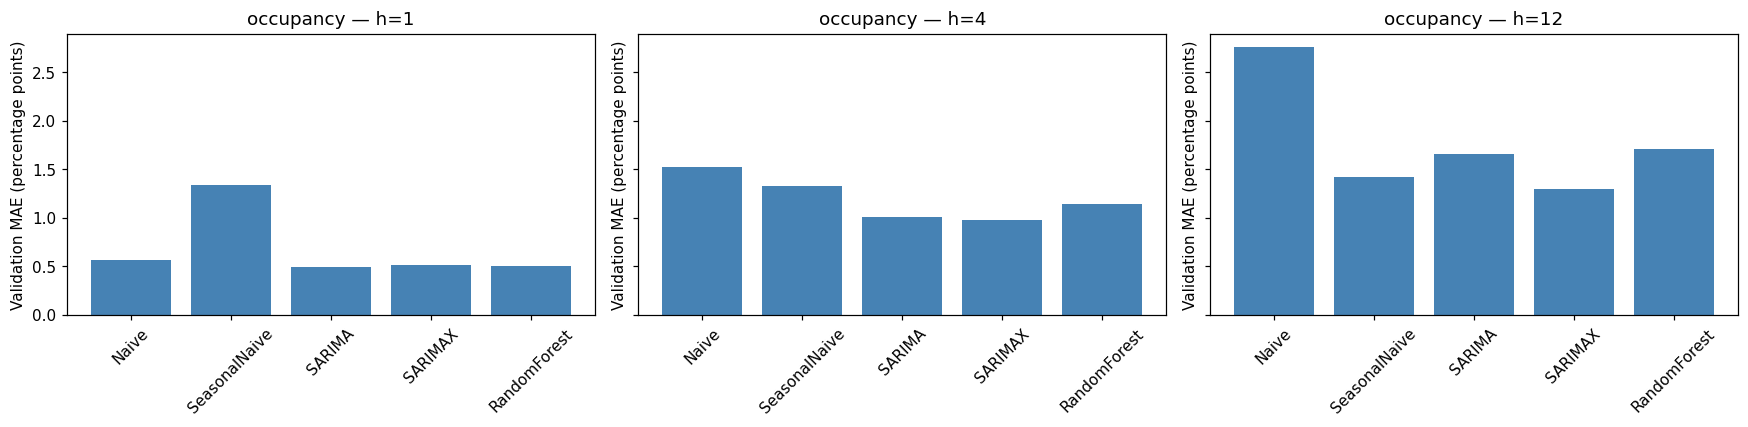

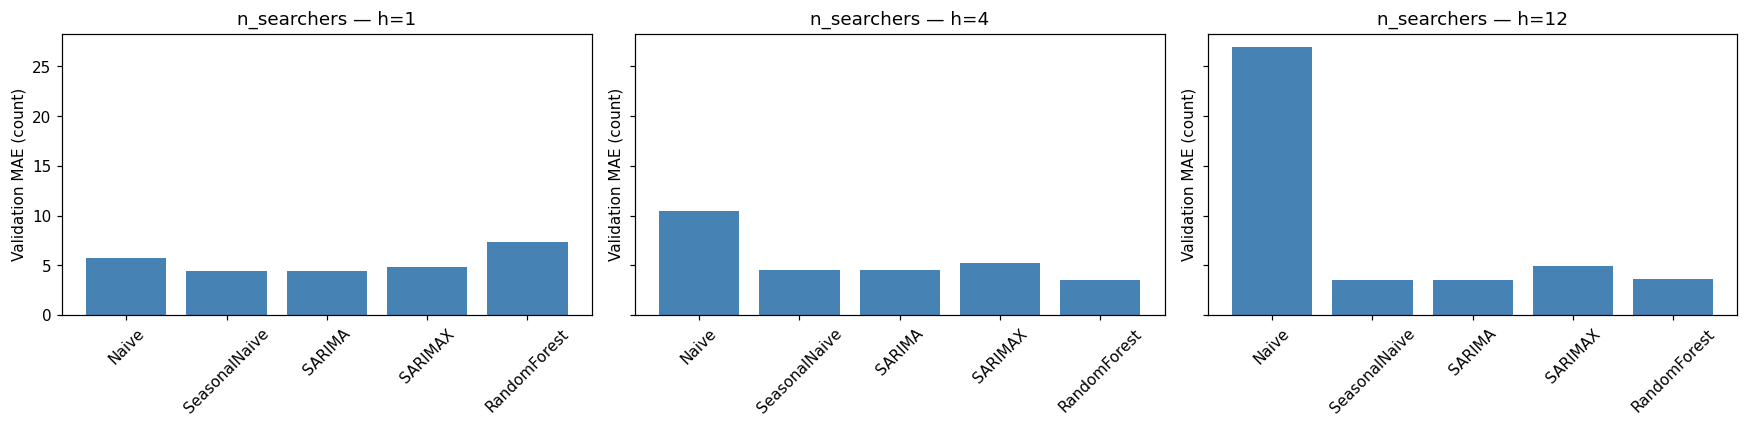

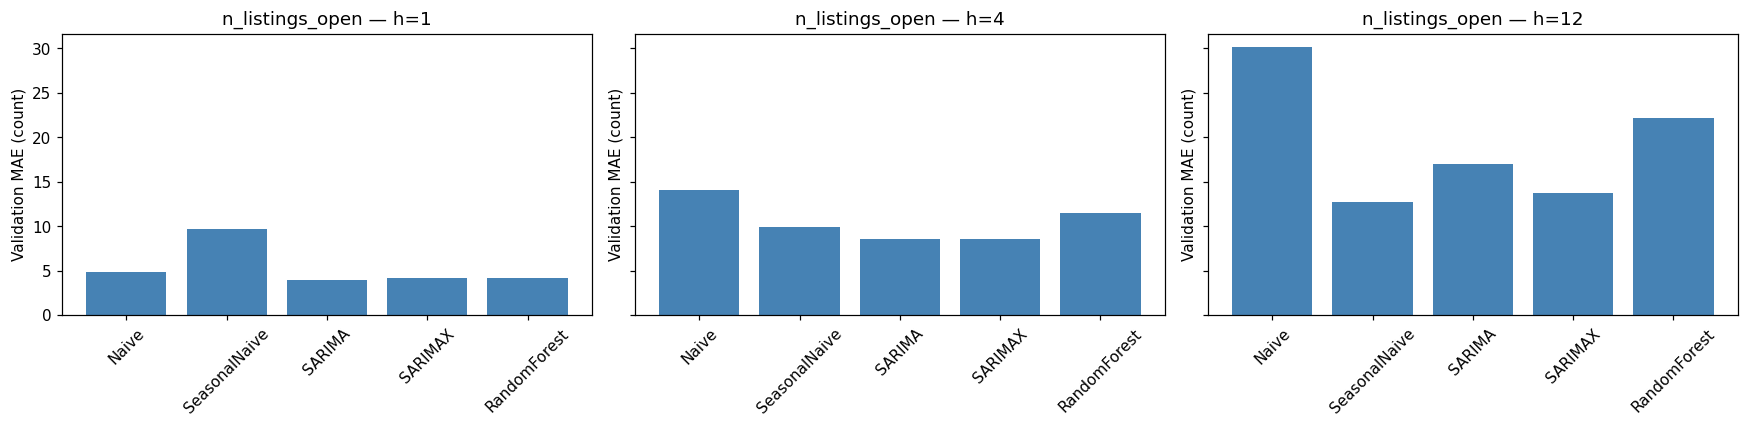

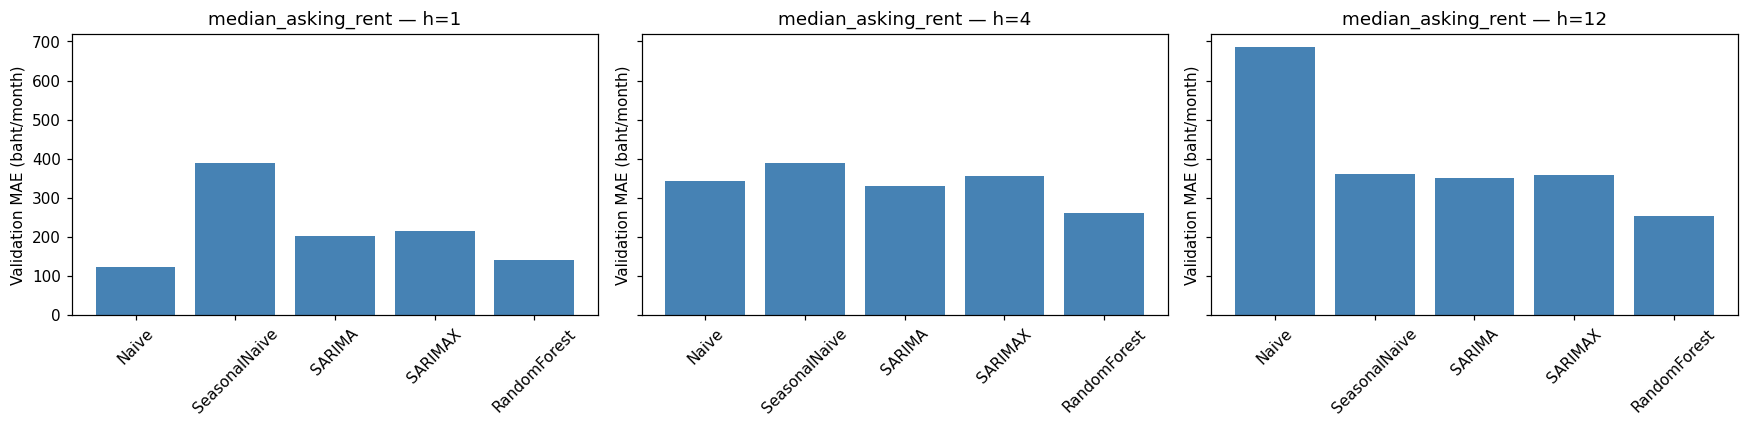

In [15]:
# วนวาดกราฟทีละ horizon; axes[index] คือกราฟย่อยลำดับนั้น
for target in target_names:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for index, horizon in enumerate(horizons):
        ax = axes[index]
        plot_data = validation_scores.loc[
            validation_scores["target"].eq(target)
            & validation_scores["horizon_weeks"].eq(horizon)
        ].copy()
        plot_data = plot_data.set_index("method")
        plot_data = plot_data.reindex(model_names)
        ax.bar(model_names, plot_data["MAE"], color="steelblue")
        ax.set_title(f"{target} — h={horizon}")
        ax.set_ylabel(f"Validation MAE ({plot_data['unit'].iloc[0]})")
        ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    fig.savefig(figure_dir / f"{target}_validation_mae.png", dpi=150, bbox_inches="tight")
    plt.show()

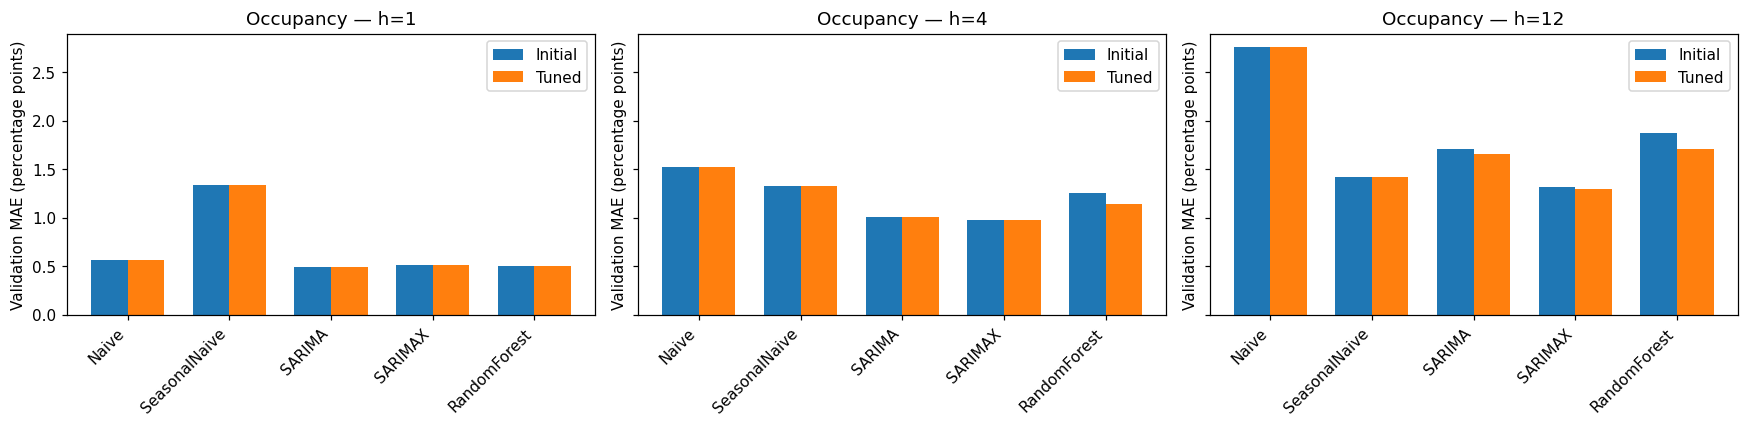

In [16]:
# วนวาดกราฟทีละ horizon; axes[index] คือกราฟย่อยลำดับนั้น
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for index, horizon in enumerate(horizons):
    ax = axes[index]
    plot_data = before_after.loc[
        before_after["target"].eq("occupancy")
        & before_after["horizon_weeks"].eq(horizon)
    ].copy()
    plot_data = plot_data.set_index("method")
    plot_data = plot_data.reindex(model_names)
    positions = np.arange(len(model_names))
    ax.bar(positions - 0.18, plot_data["MAE_before"], width=0.36, label="Initial")
    ax.bar(positions + 0.18, plot_data["MAE_after"], width=0.36, label="Tuned")
    ax.set_xticks(positions, model_names, rotation=45, ha="right")
    ax.set_title(f"Occupancy — h={horizon}")
    ax.set_ylabel("Validation MAE (percentage points)")
    ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "occupancy_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. ตัวอย่างค่าจริงและค่าพยากรณ์ occupancy

เลือกโครงการที่มีแถว Validation ร่วมกันมากที่สุดที่ horizon 4 สัปดาห์ ถ้าเท่ากันเลือก project_id ต่ำสุด
แสดงผล rolling-origin แต่ละจุดมาจาก origin ต่างกัน ไม่ใช่เส้นทางอนาคตจาก origin เดียว
กราฟนี้เป็นตัวอย่างประกอบ ค่าประเมินหลักยังรวมทุกโครงการ

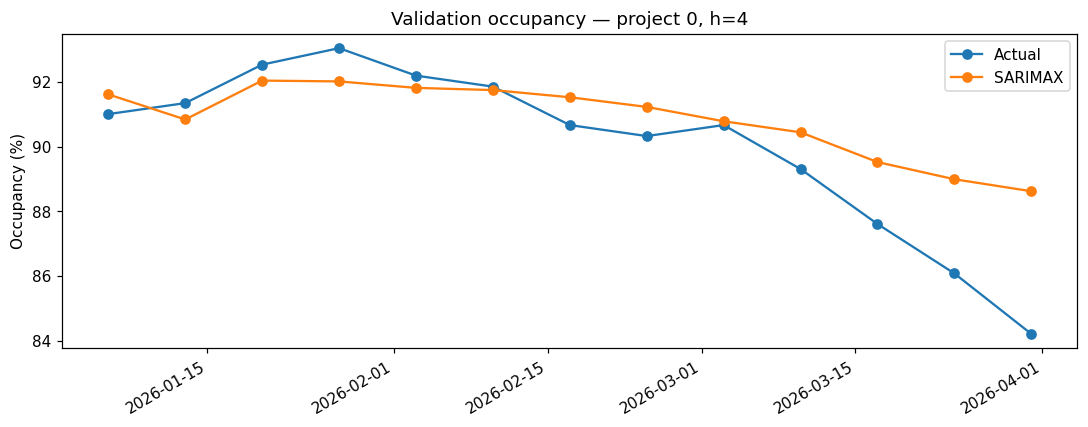

,project_id,forecast_origin,target_date,method,actual,prediction
156,0,2025-12-09,2026-01-06,SARIMAX,0.910017,0.916113
164,0,2025-12-16,2026-01-13,SARIMAX,0.913413,0.908348
172,0,2025-12-23,2026-01-20,SARIMAX,0.925297,0.920368
184,0,2025-12-30,2026-01-27,SARIMAX,0.930390,0.920110
196,0,2026-01-06,2026-02-03,SARIMAX,0.921902,0.918117
208,0,2026-01-13,2026-02-10,SARIMAX,0.918506,0.917437
220,0,2026-01-20,2026-02-17,SARIMAX,0.906621,0.915217
232,0,2026-01-27,2026-02-24,SARIMAX,0.903226,0.912233
244,0,2026-02-03,2026-03-03,SARIMAX,0.906621,0.907802
256,0,2026-02-10,2026-03-10,SARIMAX,0.893039,0.904388


In [17]:
# 1. หาว่ากรณีใดมีคำทำนายครบทั้ง 5 วิธี
# แต่ละแถวใน prediction_table คือกรณีเดียวกัน ส่วนคอลัมน์คือชื่อโมเดล
case_columns = ["target", "horizon_weeks", "project_id", "forecast_origin", "target_date"]
prediction_table = validation_predictions.pivot(
    index=case_columns, columns="method", values="prediction"
)
prediction_table = prediction_table.reindex(columns=model_names)
prediction_table = prediction_table.dropna()  # เก็บแถวที่ครบทั้ง 5 วิธี
complete_cases = prediction_table.reset_index()[case_columns]

# 2. เก็บเฉพาะกรณีที่ครบ แล้วเลือกคำทำนายของโมเดลผู้ชนะ
complete_predictions = validation_predictions.merge(
    complete_cases, on=case_columns, validate="many_to_one"
)
winner_keys = winning_models[["target", "horizon_weeks", "method"]]
selected_predictions = complete_predictions.merge(
    winner_keys, on=["target", "horizon_weeks", "method"], validate="many_to_one"
)

# 3. เลือกตัวอย่าง occupancy ล่วงหน้า 4 สัปดาห์
is_occupancy = selected_predictions["target"] == "occupancy"
is_four_weeks = selected_predictions["horizon_weeks"] == 4
occupancy_predictions = selected_predictions[is_occupancy & is_four_weeks]

# ใช้โครงการที่มีจำนวนแถวมากที่สุด ถ้าเท่ากันเลือก project_id ต่ำสุด
project_counts = occupancy_predictions.groupby("project_id").size()
project_counts = project_counts.sort_values(ascending=False, kind="stable")
example_project = project_counts.index[0]
example_data = occupancy_predictions[occupancy_predictions["project_id"] == example_project]
example_data = example_data.sort_values("target_date")

# 4. เปลี่ยนสัดส่วนเป็นเปอร์เซ็นต์แล้ววาดกราฟ
dates = example_data["target_date"]
actual_percent = example_data["actual"] * 100
predicted_percent = example_data["prediction"] * 100
chosen_model = example_data["method"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dates, actual_percent, marker="o", label="Actual")
ax.plot(dates, predicted_percent, marker="o", label=chosen_model)
ax.set_title(f"Validation occupancy — project {example_project}, h=4")
ax.set_ylabel("Occupancy (%)")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(figure_dir / "occupancy_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

example_columns = ["project_id", "forecast_origin", "target_date", "method", "actual", "prediction"]
display(example_data[example_columns])

## 9. ผล Test ของรอบแรกก่อนจูน

ตารางนี้เก็บผลเดิมของ family ที่เลือกจาก Validation รอบแรก ไม่เลือกผู้ชนะใหม่จาก Test
ค่า Test ด้านล่างไม่ใช่คะแนนของโมเดลหลังจูน ห้ามนำไปจับคู่กับ Validation หลังจูน
horizon 12 มี Test origin เดียว จึงยังบอกความสม่ำเสมอข้ามเวลาไม่ได้
ผลกลุ่มประวัติสั้นแสดงแยก เพราะไม่ได้อยู่ในชุดเปรียบเทียบหลักครบ 5 วิธี

In [18]:
display(initial_test_results.sort_values(["target", "horizon_weeks"]).round(4))
print("กลุ่มประวัติสั้น: ผล Test รอบแรกเฉพาะ Naive และ Random Forest")
display(short_history_results.sort_values(["target", "horizon_weeks", "method"]).round(4))

,target,horizon_weeks,method,Validation_MAE,unit,Test_MAE,Test_RMSE,n_predictions
0,median_asking_rent,1,Naive,123.0769,baht/month,216.0764,380.9069,144
1,median_asking_rent,4,RandomForest,263.7193,baht/month,332.4035,474.4430,108
2,median_asking_rent,12,RandomForest,291.0398,baht/month,521.4356,638.4917,12
3,n_listings_open,1,SARIMA,3.9876,count,6.7370,9.6097,144
4,n_listings_open,4,SARIMA,8.5354,count,15.8782,22.0432,108
5,n_listings_open,12,SeasonalNaive,9.9310,count,7.5000,10.0250,12
6,n_searchers,1,SARIMA,4.3562,count,9.8734,14.3684,144
7,n_searchers,4,RandomForest,3.5566,count,11.6749,19.9279,108
8,n_searchers,12,RandomForest,4.8007,count,6.7442,8.6104,12
9,occupancy,1,SARIMA,0.4920,percentage points,0.8721,1.1775,144


กลุ่มประวัติสั้น: ผล Test รอบแรกเฉพาะ Naive และ Random Forest


,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Test,72,305.9722,664.5398,305.9722,664.5398,baht/month
1,median_asking_rent,1,RandomForest,Test,72,311.5749,573.2531,311.5749,573.2531,baht/month
2,median_asking_rent,4,Naive,Test,54,655.3704,931.0548,655.3704,931.0548,baht/month
3,median_asking_rent,4,RandomForest,Test,54,642.7020,851.8377,642.7020,851.8377,baht/month
4,median_asking_rent,12,Naive,Test,6,1815.0000,2245.4602,1815.0000,2245.4602,baht/month
5,median_asking_rent,12,RandomForest,Test,6,1264.5291,1465.0060,1264.5291,1465.0060,baht/month
6,n_listings_open,1,Naive,Test,72,25.3194,36.4705,25.3194,36.4705,count
7,n_listings_open,1,RandomForest,Test,72,14.1116,20.6637,14.1116,20.6637,count
8,n_listings_open,4,Naive,Test,54,102.3519,132.9335,102.3519,132.9335,count
9,n_listings_open,4,RandomForest,Test,54,42.7194,60.5834,42.7194,60.5834,count


## 10. ตรวจจำนวนกรณีและข้อจำกัด

ข้อมูลจำลองยังไม่ยืนยันประสิทธิภาพในธุรกิจจริง และยังไม่มี Prediction Interval ที่ตรวจ coverage แล้ว
ผลจูนไม่ได้ดีขึ้นทุกงาน ต้องรายงานผลตามจริง การสร้าง occupancy ทุกสัปดาห์ 1–12
สำหรับ What-if และการเชื่อมเว็บยังเป็นขั้นถัดไป ผล h=1/4/12 ไม่ใช่เส้นทางรายสัปดาห์ครบทั้งช่วง

In [19]:
# สรุปทีละ target/horizon ด้วย for loop เพื่อเห็นที่มาของแต่ละค่า
case_rows = []
for (target, horizon), group in selected_predictions.groupby(["target", "horizon_weeks"]):
    case_rows.append({
        "target": target,
        "horizon_weeks": horizon,
        "projects": group["project_id"].nunique(),
        "origins": group["forecast_origin"].nunique(),
        "first_origin": group["forecast_origin"].min(),
        "last_origin": group["forecast_origin"].max(),
        "n_predictions": len(group),
    })
case_summary = pd.DataFrame(case_rows)
display(case_summary)

# ตรวจว่าจำนวนแถวที่เราอ่านได้ตรงกับจำนวนในรายงานเดิม
count_check = case_summary.merge(
    winning_models[["target", "horizon_weeks", "n_predictions"]],
    on=["target", "horizon_weeks"],
    suffixes=("_observed", "_reported"), validate="one_to_one",
)
counts_match = count_check["n_predictions_observed"] == count_check["n_predictions_reported"]
assert counts_match.all(), "จำนวนแถวไม่ตรงกับรายงานเดิม"
assert len(winning_models) == 12, "ต้องมีผู้ชนะ 4 targets × 3 horizons"
assert tuned_model_info["test_reopened"] is False

print("โมเดลที่บันทึก:", project_root / "models/market_occupancy/tuned/selected_models.joblib")
print("ข้อจำกัด: ยังไม่มีผล final holdout ใหม่สำหรับโมเดลหลังจูน")

,target,horizon_weeks,projects,origins,first_origin,last_origin,n_predictions
0,median_asking_rent,1,12,13,2025-12-30,2026-03-24,156
1,median_asking_rent,4,12,13,2025-12-09,2026-03-03,148
2,median_asking_rent,12,12,7,2025-11-25,2026-01-06,68
3,n_listings_open,1,12,13,2025-12-30,2026-03-24,156
4,n_listings_open,4,12,13,2025-12-09,2026-03-03,148
5,n_listings_open,12,12,7,2025-11-25,2026-01-06,68
6,n_searchers,1,12,13,2025-12-30,2026-03-24,156
7,n_searchers,4,12,13,2025-12-09,2026-03-03,148
8,n_searchers,12,12,7,2025-11-25,2026-01-06,68
9,occupancy,1,12,13,2025-12-30,2026-03-24,156


โมเดลที่บันทึก: D:\final project_\models\market_occupancy\tuned\selected_models.joblib
ข้อจำกัด: ยังไม่มีผล final holdout ใหม่สำหรับโมเดลหลังจูน


## 11. ส่งออกตารางและสรุปสำหรับรายงาน

สรุปด้านล่างสร้างจากตัวเลขจริงในไฟล์ผลทดลอง ไม่เขียนค่าคะแนนตายตัว
บันทึกเฉพาะผลสรุปใน reports/market_occupancy/final_results

In [20]:
# บันทึกตารางที่เตรียมไว้ในขั้นก่อนหน้า
selected_results.to_csv(output_dir / "selected_tuned_validation_models.csv", index=False, encoding="utf-8-sig")
tuning_changes.to_csv(output_dir / "tuning_before_after.csv", index=False, encoding="utf-8-sig")
selected_parameters.to_csv(output_dir / "selected_hyperparameters.csv", index=False, encoding="utf-8-sig")
initial_test_results.to_csv(output_dir / "initial_round_test_results.csv", index=False, encoding="utf-8-sig")
case_summary.to_csv(output_dir / "validation_case_summary.csv", index=False, encoding="utf-8-sig")
experiment_design.to_csv(output_dir / "experiment_design.csv", index=False, encoding="utf-8-sig")

In [21]:
# สร้างข้อความสรุปจากคะแนนจริง ไม่เขียนคะแนนตายตัว
summary_lines = [
    "# สรุปผลวัตถุประสงค์ข้อ 2", "",
    "เพื่อพัฒนาโมเดลพยากรณ์สภาวะตลาดและอัตราการเข้าพักล่วงหน้า (Market & Occupancy Forecasting)", "",
    "ทดลอง SARIMA, SARIMAX และ Random Forest พร้อม Naive และ Seasonal Naive บนข้อมูลจำลองของโครงงาน",
    "เลือกพารามิเตอร์ด้วย rolling-origin ภายใน Train แล้วเลือก family ด้วย Validation MAE แยก target/horizon", "",
    f"จูนได้ {len(cv_scores)} ชุดคะแนน CV ผล Validation ของ 36 งานดีขึ้น {change_counts['ดีขึ้น']} งาน "
    f"แย่ลง {change_counts['แย่ลง']} งาน และเท่าเดิม {change_counts['เท่าเดิม']} งาน", "",
    "| Target | Horizon (สัปดาห์) | วิธีที่เลือก | Validation MAE หลังจูน | RMSE | หน่วย | จำนวนกรณี |",
    "|---|---:|---|---:|---:|---|---:|",
]
for row in selected_results.sort_values(["target", "horizon_weeks"]).itertuples():
    summary_lines.append(
        f"| {row.target} | {row.horizon_weeks} | {row.method} | "
        f"{row.MAE:.4f} | {row.RMSE:.4f} | {row.unit} | {row.n_predictions} |"
    )
summary_lines += ["", "ข้อสรุปและข้อจำกัด:", "",
    "- baseline ชนะบางงาน จึงไม่มีโมเดลเดียวดีที่สุดทุก target/horizon",
    "- ก่อน/หลังจูนเปรียบเทียบบนแถวเดียวกัน; Validation origin หลังจูนไม่ก่อน 25 พฤศจิกายน 2025",
    "- การจูนเป็น small-grid search: 3 candidates ต่อ family และ 4 origins ไม่ใช่ exhaustive search",
    "- ผล Test ใน Notebook เป็นรอบแรกก่อนจูนเท่านั้น; โมเดลหลังจูนยังไม่มี final holdout ใหม่",
    "- Test h=12 รอบแรกมี origin เดียว; ต้องเพิ่มข้อมูลเพื่อประเมินความสม่ำเสมอข้ามเวลา",
    "- ใช้ข้อมูลจำลอง ไม่อ้างเป็นประสิทธิภาพที่ยืนยันในธุรกิจจริง",
    "- ยังไม่มี Prediction Interval ที่ตรวจสอบแล้ว และยังไม่เชื่อม Web/What-if รายสัปดาห์ครบ 1–12", "",
    "โมเดลหลังจูน: models/market_occupancy/tuned/selected_models.joblib",
    "แหล่งผล: reports/market_occupancy/tuning และ evaluation",
]
final_summary = "\n".join(summary_lines)
(output_dir / "objective2_final_summary.md").write_text(final_summary, encoding="utf-8")
display(Markdown(final_summary))
print("บันทึกผลสรุปที่:", output_dir)

# สรุปผลวัตถุประสงค์ข้อ 2

เพื่อพัฒนาโมเดลพยากรณ์สภาวะตลาดและอัตราการเข้าพักล่วงหน้า (Market & Occupancy Forecasting)

ทดลอง SARIMA, SARIMAX และ Random Forest พร้อม Naive และ Seasonal Naive บนข้อมูลจำลองของโครงงาน
เลือกพารามิเตอร์ด้วย rolling-origin ภายใน Train แล้วเลือก family ด้วย Validation MAE แยก target/horizon

จูนได้ 108 ชุดคะแนน CV ผล Validation ของ 36 งานดีขึ้น 13 งาน แย่ลง 10 งาน และเท่าเดิม 13 งาน

| Target | Horizon (สัปดาห์) | วิธีที่เลือก | Validation MAE หลังจูน | RMSE | หน่วย | จำนวนกรณี |
|---|---:|---|---:|---:|---|---:|
| median_asking_rent | 1 | Naive | 123.0769 | 196.0262 | baht/month | 156 |
| median_asking_rent | 4 | RandomForest | 262.0789 | 321.6435 | baht/month | 148 |
| median_asking_rent | 12 | RandomForest | 253.0383 | 320.7927 | baht/month | 68 |
| n_listings_open | 1 | SARIMA | 3.9876 | 5.2691 | count | 156 |
| n_listings_open | 4 | SARIMA | 8.5354 | 10.8008 | count | 148 |
| n_listings_open | 12 | SeasonalNaive | 12.6912 | 16.6225 | count | 68 |
| n_searchers | 1 | SARIMA | 4.4084 | 6.0526 | count | 156 |
| n_searchers | 4 | RandomForest | 3.5657 | 4.6855 | count | 148 |
| n_searchers | 12 | SARIMA | 3.5294 | 4.6873 | count | 68 |
| occupancy | 1 | SARIMA | 0.4920 | 0.6339 | percentage points | 156 |
| occupancy | 4 | SARIMAX | 0.9809 | 1.2673 | percentage points | 148 |
| occupancy | 12 | SARIMAX | 1.3009 | 1.6639 | percentage points | 68 |

ข้อสรุปและข้อจำกัด:

- baseline ชนะบางงาน จึงไม่มีโมเดลเดียวดีที่สุดทุก target/horizon
- ก่อน/หลังจูนเปรียบเทียบบนแถวเดียวกัน; Validation origin หลังจูนไม่ก่อน 25 พฤศจิกายน 2025
- การจูนเป็น small-grid search: 3 candidates ต่อ family และ 4 origins ไม่ใช่ exhaustive search
- ผล Test ใน Notebook เป็นรอบแรกก่อนจูนเท่านั้น; โมเดลหลังจูนยังไม่มี final holdout ใหม่
- Test h=12 รอบแรกมี origin เดียว; ต้องเพิ่มข้อมูลเพื่อประเมินความสม่ำเสมอข้ามเวลา
- ใช้ข้อมูลจำลอง ไม่อ้างเป็นประสิทธิภาพที่ยืนยันในธุรกิจจริง
- ยังไม่มี Prediction Interval ที่ตรวจสอบแล้ว และยังไม่เชื่อม Web/What-if รายสัปดาห์ครบ 1–12

โมเดลหลังจูน: models/market_occupancy/tuned/selected_models.joblib
แหล่งผล: reports/market_occupancy/tuning และ evaluation

บันทึกผลสรุปที่: D:\final project_\reports\market_occupancy\final_results
